In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import parser_functions as pf
from pathlib import Path
from scipy import stats
import sys
import os
from scipy.ndimage import gaussian_filter1d

import importlib
importlib.reload(pf)




<module 'parser_functions' from '/Users/sandrareinert/Library/Mobile Documents/com~apple~CloudDocs/Documents/Postdoc_SWC/Code/Meg_mini/parser_functions.py'>

In [12]:
DATA_DIR = Path(
    "/Users/sandrareinert/Library/Mobile Documents/com~apple~CloudDocs/Documents/"
    "Postdoc_SWC/Local_bits/meg_hackathon/data"
)

TRIAL_COLS = [
    "trial_index", "blocks", "trials_in_block", "choice", "chosen_rank",
    "chosen_magnitude", "trial_start_s", "trial_end_s",
]

In [66]:
df = pf.load_run("ses-218", "run-01", data_dir=DATA_DIR)
trials = pf.get_trials(df)
F = pf.get_F(df)

In [67]:
trials

,trial_index,blocks,trials_in_block,choice,chosen_rank,chosen_magnitude,trial_start_s,trial_end_s,init_cue_frame,reward_frame
0,0,1.0,21.0,C3,third,0.0,0.001,82.614,71,<NA>
1,1,1.0,22.0,A1,best,3.0,82.614,153.597,1152,1184
2,2,1.0,23.0,A1,best,3.0,153.597,175.452,1318,1348
3,3,1.0,24.0,A1,best,3.0,175.452,270.544,2042,2063
4,4,1.0,25.0,C3,third,0.0,270.544,302.045,2264,<NA>
5,5,1.0,26.0,A1,best,3.0,302.045,365.305,2730,2776
6,6,1.0,27.0,A1,best,3.0,365.305,390.621,2926,2966
7,7,1.0,28.0,C3,third,0.0,390.621,503.385,3797,<NA>
8,8,1.0,29.0,C3,third,0.0,503.385,554.037,4046,<NA>


/Users/sandrareinert/Library/Mobile Documents/com~apple~CloudDocs/Documents/Postdoc_SWC/Code/Meg_mini/parser_functions.py:132: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(traces, axis=0) if np.isfinite(traces).any() else np.full(traces.shape[1:], np.nan)


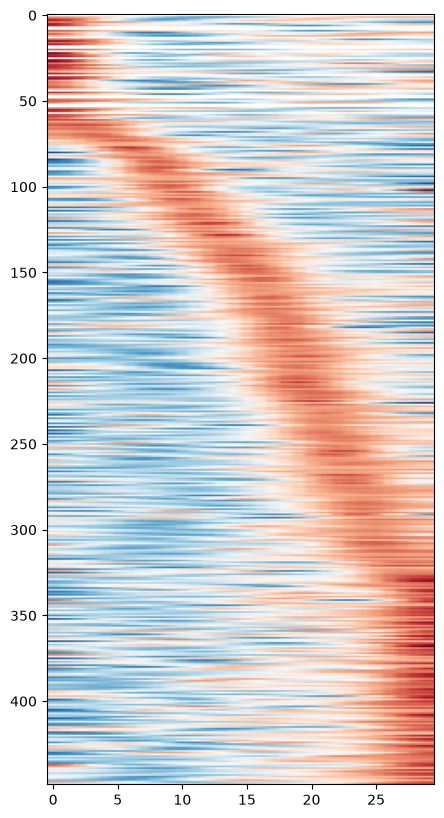

In [68]:
event_frames = trials["reward_frame"].to_numpy()
traces, mean, t = pf.psth(F[0], event_frames, window=(-2, 2), fs = 7.52, smooth_sigma=3.0)
#mean of even trials
zsc_mean = stats.zscore(mean, axis=1)
#sort based on when the peak occurs
sorted_idx = np.argsort(np.argmax(zsc_mean, axis=1))
plt.figure(figsize=(5, 10))
plt.imshow(zsc_mean[sorted_idx, :], aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)

/Users/sandrareinert/Library/Mobile Documents/com~apple~CloudDocs/Documents/Postdoc_SWC/Code/Meg_mini/parser_functions.py:132: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(traces, axis=0) if np.isfinite(traces).any() else np.full(traces.shape[1:], np.nan)
/Users/sandrareinert/Library/Mobile Documents/com~apple~CloudDocs/Documents/Postdoc_SWC/Code/Meg_mini/parser_functions.py:132: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(traces, axis=0) if np.isfinite(traces).any() else np.full(traces.shape[1:], np.nan)


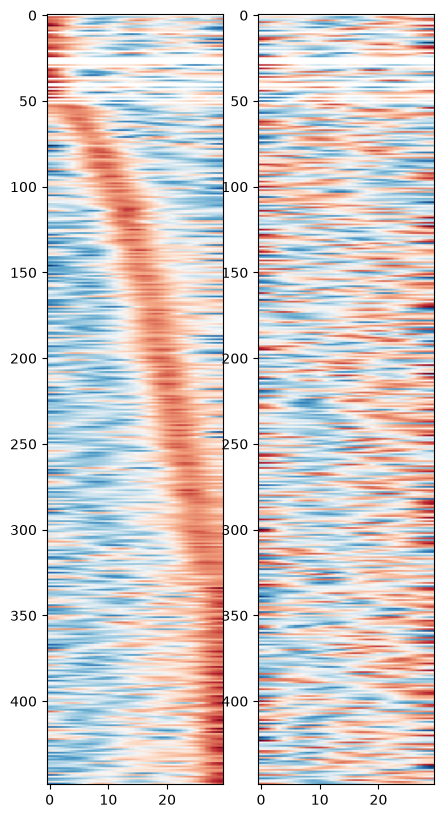

In [69]:
# for cross validation, we can split the trials into even and odd trials and compute the psth for each group separately. This will allow us to see if the patterns we observe are consistent across different subsets of the data.
even_event_frames = event_frames[::2]
odd_event_frames = event_frames[1::2]
traces_even, mean_even, t = pf.psth(F[0], even_event_frames, window=(-2, 2), fs = 7.52, smooth_sigma=3.0)
traces_odd, mean_odd, t = pf.psth(F[0], odd_event_frames, window=(-2, 2), fs = 7.52, smooth_sigma=3.0)
#mean of even trials
zsc_mean_even = stats.zscore(mean_even, axis=1)
#sort based on when the peak occurs
sorted_idx_even = np.argsort(np.argmax(zsc_mean_even, axis=1))
plt.figure(figsize=(5, 10))
plt.subplot(121)
plt.imshow(zsc_mean_even[sorted_idx_even, :], aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
#mean of odd trials
zsc_mean_odd = stats.zscore(mean_odd, axis=1)
#sort based on when the peak occurs
sorted_idx_odd = np.argsort(np.argmax(zsc_mean_odd, axis=1))
plt.subplot(122)
plt.imshow(zsc_mean_odd[sorted_idx_even, :], aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)

/Users/sandrareinert/Library/Mobile Documents/com~apple~CloudDocs/Documents/Postdoc_SWC/Code/Meg_mini/parser_functions.py:132: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(traces, axis=0) if np.isfinite(traces).any() else np.full(traces.shape[1:], np.nan)


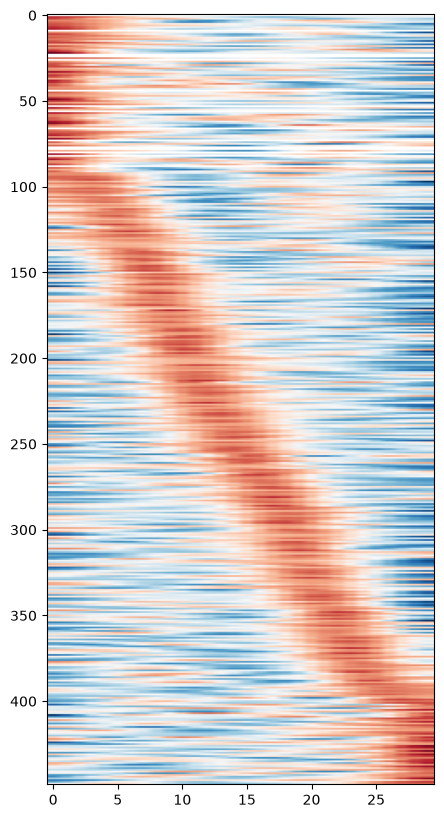

In [70]:
#same for trial initiation cue
init_cue_frames = trials["init_cue_frame"].to_numpy()
traces_init_cue, mean_init_cue, t = pf.psth(F[0], init_cue_frames, window=(-2, 2), fs = 7.52, smooth_sigma=3.0)

zsc_mean_init_cue = stats.zscore(mean_init_cue, axis=1)
sorted_idx_init_cue = np.argsort(np.argmax(zsc_mean_init_cue, axis=1))

plt.figure(figsize=(5, 10))
plt.imshow(zsc_mean_init_cue[sorted_idx_init_cue, :], aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)

In [62]:
rois_by_session, ses2uid, uid2ses = pf.get_roi_ids(DATA_DIR)

In [73]:
rois_by_session.keys()

dict_keys(['ses-216_01', 'ses-216_02', 'ses-216_03', 'ses-216_04', 'ses-216_05', 'ses-216_06', 'ses-216_07', 'ses-217_01', 'ses-217_02', 'ses-217_03', 'ses-218_01', 'ses-218_02', 'ses-218_03', 'ses-218_04', 'ses-218_05', 'ses-219_01', 'ses-219_02', 'ses-219_03', 'ses-219_04', 'ses-219_05', 'ses-219_06', 'ses-220_01', 'ses-220_02', 'ses-220_03', 'ses-220_04', 'ses-221_01', 'ses-221_02', 'ses-221_03', 'ses-221_04', 'ses-221_05', 'ses-221_06', 'ses-222_01', 'ses-222_02', 'ses-222_03', 'ses-223_01', 'ses-223_02', 'ses-223_03', 'ses-223_04', 'ses-224_01', 'ses-224_02', 'ses-224_03', 'ses-225_01', 'ses-225_02', 'ses-225_03', 'ses-225_04', 'ses-225_05', 'ses-226_01', 'ses-226_02', 'ses-226_03', 'ses-227_01', 'ses-227_02', 'ses-227_03', 'ses-227_04', 'ses-228_01', 'ses-228_02', 'ses-228_03', 'ses-228_04', 'ses-229_01', 'ses-229_02', 'ses-229_03', 'ses-229_04', 'ses-230_01', 'ses-230_02', 'ses-230_03', 'ses-230_04', 'ses-231_01', 'ses-231_02', 'ses-231_03'])